# Baseline de la cátedra (diapositiva) con el código de la plantilla z495
Mismo código y mismo orden de celdas que la plantilla de la cátedra (Tarea para el Hogar 04: `mlr3mbo`, `particionar`, `loguear`). Todo lo demás sigue la diapositiva *Baseline*:

| Diapositiva | Cómo queda en esta notebook |
|---|---|
| 762 columnas para entrenar | Se imprime la cantidad real antes de la optimización |
| Data quality | En cada `foto_mes`, variable con todos los valores en cero y sin NA pasa a NA |
| FE histórico | lag1, lag2, delta1 y delta2 de todas las variables menos `numero_de_cliente`, `foto_mes` y `clase_ternaria` |
| Búsqueda | `semilla_primigenia` 585581, `ksemillerio` 1, `repe` 1, `iteraciones` 10, `undersampling` 0,1, `training_pct` 70 |
| Fijos | `min_data_in_leaf` 0, `feature_fraction` 0,5, `feature_fraction_bynode` 0,2, `learning_rate` 0,005 |
| Bordes | `num_iterations` 64–4096, `num_leaves` 16–2048, `min_sum_hessian_in_leaf` 1e-6–0,1 |
| Producción | Entrena con 202103+202104, predice 202106, **10 semillas**, `undersampling` 0,1 |
| A reportar | AUC, mejores hiperparámetros, ganancia máxima y cantidad de envíos |

**Cambios respecto de z495 (todos para respetar la diapositiva):**
- Sin Salsa Mágica: no se sacan `cprestamos_personales` ni `mprestamos_personales`.
- Se entrena con 202103 y 202104 (la plantilla usaba solo 202104) y se agregan data quality y lags/deltas.
- Se agrega `feature_fraction_bynode` = 0,2 a los parámetros fijos.
- La validación es el 30 % limpio (`fold == 2`, ~97.800 filas) y no `training == 0`: este último incluye también los CONTINUA que el undersampling descartó del 70 % de entrenamiento (~300.900 filas).
- La métrica de la búsqueda es `auc` (la plantilla usaba `average_precision`).
- La plantilla pedía `n_evals = 10`, pero el diseño inicial de `mlr3mbo` ya evalúa 12 configuraciones y la búsqueda terminaba ahí, sin ninguna iteración bayesiana. Acá el terminador es 12 + 10 = 22 evaluaciones y se imprime cuántas se hicieron.
- Producción con 10 semillas (se promedian las probabilidades). Las semillas son 10 primos sorteados a partir de la semilla primigenia.
- Corre en local (sin Colab ni Drive).
- Si ya existe `BO_log.txt` en la carpeta del experimento, se archiva con fecha y hora antes de la BO, y producción verifica que el log tenga solo las 22 evaluaciones de esta corrida.

**Memoria:** los lags sobre 202103, 202104 y 202106 ocupan varios GB. Cerrá los otros kernels antes de correr.

## 1. Seteo del ambiente local

In [1]:
# instala solo lo que falta (la primera vez puede tardar)
paquetes <- c("data.table", "R.utils", "rlist", "bbotk", "mlr3", "mlr3mbo", "mlr3learners", "DiceKriging", "lightgbm")
faltan <- paquetes[!sapply(paquetes, requireNamespace, quietly = TRUE)]
if (length(faltan) > 0) install.packages(faltan)

In [2]:
# limpio la memoria
rm(list = ls(all.names = TRUE)) # remove all objects
gc(full = TRUE, verbose = FALSE) # garbage collection

library(data.table)
library(R.utils)
library(rlist)
library(bbotk)
library(mlr3)
library(mlr3mbo)
library(mlr3learners)
# library(paradox)
library(DiceKriging)
library(lightgbm)

RNGkind("L'Ecuyer-CMRG") # generador de la plantilla, fijo para todo el script
options(scipen = 999)

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2240822,119.7,4441967,237.3,3021510,161.4
Vcells,3649334,27.9,8388608,64.0,8313612,63.5


Caricamento del pacchetto richiesto: R.oo

Caricamento del pacchetto richiesto: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Caricamento pacchetto: 'R.oo'


Il seguente oggetto è mascherato da 'package:R.methodsS3':

    throw


I seguenti oggetti sono mascherati da 'package:methods':

    getClasses, getMethods


I seguenti oggetti sono mascherati da 'package:base':

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Caricamento pacchetto: 'R.utils'


Il seguente oggetto è mascherato da 'package:utils':

    timestamp


I seguenti oggetti sono mascherati da 'package:base':

    cat, commandArgs, getOption, isOpen, nullfile, parse, use, warnings


Caricamento del pacchetto richiesto: paradox


Caricamento pacchetto: 'mlr3'


Il seguente oggetto è mascherato da 'package:R.util

## 2. Definicion de Parametros

In [3]:
PARAM <- list()
PARAM$experimento <- "Baseline_diapo"
PARAM$semilla_primigenia <- 585581   # La semilla de Laura Pasquini

# carpetas locales
PARAM$data_dir <- "C:/Users/Laura/Documents/DMEyF/datasets/"
PARAM$exp_dir  <- "C:/Users/Laura/Documents/DMEyF/exp/"

In [4]:
# training y future
PARAM$training_pct <- 70
PARAM$train <- c(202103, 202104)
PARAM$train_final <- c(202103, 202104)
PARAM$future <- c(202106)
PARAM$cortes <- seq(9000, 15000, by = 500)

In [5]:
# un undersampling de 0.1  toma solo el 10% de los CONTINUA
# undersampling de 1.0  implica tomar TODOS los datos

PARAM$trainingstrategy$undersampling <- 0.1

In [6]:
# diapositiva: ksemillerio 1, repe 1, iteraciones 10
PARAM$hyperparametertuning$ksemillerio <- 1   # con 1 y 1 hay una sola particion y una sola semilla en la busqueda
PARAM$hyperparametertuning$repe <- 1
PARAM$hyperparametertuning$iteraciones <- 10  # iteraciones bayesianas
PARAM$hyperparametertuning$init <- 12         # diseno inicial de mlr3mbo (4 x 3 hiperparametros), no cuenta como iteracion

# diapositiva: produccion con 10 semillas
PARAM$semillas_finales_n <- 10

In [7]:
# Parametros LightGBM

# parametros fijos del LightGBM que se pisaran con la parte variable de la BO
PARAM$lgbm$param_fijos <- list(
  boosting = "gbdt", # puede ir  dart  , ni pruebe random_forest
  objective = "binary",
  metric = "auc",    # la diapositiva pide reportar AUC
  feature_pre_filter = FALSE,
  first_metric_only = FALSE,
  boost_from_average = TRUE,
  force_row_wise = TRUE,
  deterministic = TRUE,
  verbosity = -100,

  seed = PARAM$semilla_primigenia,

  max_depth = -1L,
  min_gain_to_split = 0,
  lambda_l1 = 0.0,
  lambda_l2 = 0.0,
  max_bin = 31L,

  bagging_fraction = 1.0,
  pos_bagging_fraction = 1.0,
  neg_bagging_fraction = 1.0,
  is_unbalance = FALSE,
  scale_pos_weight = 1.0,

  drop_rate = 0.1,
  max_drop = 50,
  skip_drop = 0.5,

  extra_trees = FALSE,

  early_stopping = 0,
  min_data_in_leaf = 0,           # fijo, esto es FUNDAMENTAL
  feature_fraction = 0.50,        # fijo
  feature_fraction_bynode = 0.20, # fijo (diapositiva)
  learning_rate = 0.005,          # fijo

  num_iterations = 20000,    # se modificara
  num_leaves = 1024,         # se modificara
  min_sum_hessian_in_leaf = 1e-06  # se modificara
)

Aqui se definen los hiperparámetros de LightGBM que participan de la Bayesian Optimization

In [8]:
# Aqui se cargan los bordes de los hiperparametros de la BO
#  es vital entender que se optimiza min_sum_hessian_in_leaf y que  min_data_in_leaf se deja fijo en CERO

PARAM$hypeparametertuning$hs <- ps(
  num_iterations = p_int(lower = 64L, upper = 4096L),
  num_leaves = p_int(lower = 16L, upper = 2048L),
  min_sum_hessian_in_leaf = p_dbl(lower = 1e-06, upper = 0.1)
)

In [9]:
# particionar agrega una columna llamada fold a un dataset
#   que consiste en una particion estratificada segun agrupa
# particionar( data=dataset, division=c(70,30),
#  agrupa=clase_ternaria, seed=semilla)   crea una particion 70, 30

particionar <- function(data, division, agrupa = "", campo = "fold", start = 1, seed = NA) {
  if (!is.na(seed)) set.seed(seed, "L'Ecuyer-CMRG")

  bloque <- unlist(mapply(
    function(x, y) {rep(y, x)}, division, seq(from = start, length.out = length(division))))

  data[, (campo) := sample(rep(bloque, ceiling(.N / length(bloque))))[1:.N], by = agrupa]
}

In [10]:
# logueo al archivo BO_log.txt
loguear <- function(preg, arch = NA, verbose = TRUE)
{
  t0 <- Sys.time()
  reg <- copy(preg)
  if ("feature_contri" %in% names(reg)) {
    reg$feature_contri <- reg$feature_contri[1]
  }
  archivo <- arch
  if (is.na(arch)) archivo <- paste0(folder, substitute(reg), ext)


  if (!file.exists(archivo))
  {
    # Escribo los titulos
    linea <- paste0("fecha\t",
                    paste(list.names(reg), collapse = "\t"), "\n")

    cat(linea, file = archivo)
  }

  # escribo el registro
  linea <- paste0(format(t0, "%Y%m%d.%H%M%S"), "\t",     # la fecha y hora
                  gsub(", ", "\t", toString(reg)), "\n")

  cat(linea, file = archivo, append = TRUE)  # grabo al archivo

  if (verbose) cat(linea)   # imprimo por pantalla
}

## 3. Generacion de la clase_ternaria (solo si no existe `competencia_01.csv`)

In [11]:
archivo_crudo    <- file.path(PARAM$data_dir, "competencia_01_crudo.csv")
archivo_ternaria <- file.path(PARAM$data_dir, "competencia_01.csv")

if (!file.exists(archivo_ternaria)) {
  if (!file.exists(archivo_crudo)) stop("No encuentro ni competencia_01.csv ni competencia_01_crudo.csv en ", PARAM$data_dir)

  dataset <- fread(archivo_crudo)

  # calculo el periodo0 consecutivo
  dsimple <- dataset[, list(
    "pos" = .I,
    numero_de_cliente,
    periodo0 = as.integer(foto_mes / 100) * 12 + foto_mes %% 100)]

  # ordeno
  setorder(dsimple, numero_de_cliente, periodo0)

  # calculo topes
  periodo_ultimo <- dsimple[, max(periodo0)]
  periodo_anteultimo <- periodo_ultimo - 1

  # calculo los leads de orden 1 y 2
  dsimple[, c("periodo1", "periodo2") :=
    shift(periodo0, n = 1:2, fill = NA, type = "lead"), numero_de_cliente]

  # assign most common class values = "CONTINUA"
  dsimple[periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA"]

  # calculo BAJA+1
  dsimple[periodo0 < periodo_ultimo &
    (is.na(periodo1) | periodo0 + 1 < periodo1),
    clase_ternaria := "BAJA+1"]

  # calculo BAJA+2
  dsimple[periodo0 < periodo_anteultimo & (periodo0 + 1 == periodo1)
    & (is.na(periodo2) | periodo0 + 2 < periodo2),
    clase_ternaria := "BAJA+2"]

  # pego el resultado en el dataset original y grabo
  setorder(dsimple, pos)
  dataset[, clase_ternaria := dsimple$clase_ternaria]
  fwrite(dataset, file = archivo_ternaria, sep = ",")
  rm(dataset, dsimple); gc()
}
cat("Uso:", archivo_ternaria, "\n")

Uso: C:/Users/Laura/Documents/DMEyF/datasets//competencia_01.csv 


## 4. Preprocesamiento

In [12]:
# carpeta de trabajo
dir.create(file.path(PARAM$exp_dir, PARAM$experimento), showWarnings = FALSE, recursive = TRUE)
setwd(file.path(PARAM$exp_dir, PARAM$experimento))

# lectura del dataset (solo hasta el mes del future: no hace falta mas)
dataset <- fread(archivo_ternaria, stringsAsFactors = TRUE)
dataset <- dataset[foto_mes <= max(PARAM$future)]
stopifnot("clase_ternaria" %in% colnames(dataset))
setorder(dataset, numero_de_cliente, foto_mes)
cat("Meses:", paste(sort(unique(dataset$foto_mes)), collapse = ", "), "|", nrow(dataset), "filas x", ncol(dataset), "columnas\n")

Meses: 202103, 202104, 202105, 202106 | 654066 filas x 155 columnas


### 4.1 Data quality
En cada `foto_mes`, la variable con **todos** sus valores exactamente en cero y **ningún** NA pasa a NA (como `ccajas_depositos` en 202105).

In [13]:
campos_excluidos <- c("numero_de_cliente", "foto_mes", "clase_ternaria")
campos_dq <- setdiff(colnames(dataset), campos_excluidos)
campos_dq <- campos_dq[sapply(dataset[, ..campos_dq], is.numeric)]

correcciones <- list()
for (mes in sort(unique(dataset$foto_mes))) {
  filas <- which(dataset$foto_mes == mes)
  for (campo in campos_dq) {
    x <- dataset[[campo]][filas]
    if (!anyNA(x) && all(x == 0)) {
      set(dataset, i = filas, j = campo, value = NA)
      correcciones[[length(correcciones) + 1]] <- data.table(foto_mes = mes, variable = campo, filas = length(filas))
    }
  }
}
correcciones <- rbindlist(correcciones)
cat("Variables pasadas a NA por mes:", nrow(correcciones), "\n")
if (nrow(correcciones) > 0) {
  print(correcciones)
  fwrite(correcciones, "data_quality_correcciones.csv")
}

Variables pasadas a NA por mes: 1 
   foto_mes         variable  filas
      <int>           <char>  <int>
1:   202105 ccajas_depositos 163768


### 4.2 FE histórico: lags y delta lags de orden 1 y 2

In [14]:
campos_lag <- setdiff(colnames(dataset), campos_excluidos)
campos_lag <- campos_lag[sapply(dataset[, ..campos_lag], is.numeric)]
cat("Lags y deltas para", length(campos_lag), "variables\n")

t0 <- Sys.time()
dataset[, (paste0(campos_lag, "_lag1")) := shift(.SD, n = 1, fill = NA, type = "lag"), by = numero_de_cliente, .SDcols = campos_lag]
dataset[, (paste0(campos_lag, "_lag2")) := shift(.SD, n = 2, fill = NA, type = "lag"), by = numero_de_cliente, .SDcols = campos_lag]
for (campo in campos_lag) {
  dataset[, paste0(campo, "_delta1") := get(campo) - get(paste0(campo, "_lag1"))]
  dataset[, paste0(campo, "_delta2") := get(campo) - get(paste0(campo, "_lag2"))]
}
cat("Listo en", round(as.numeric(Sys.time() - t0, units = "secs"), 1), "seg |", ncol(dataset), "columnas\n")

Lags y deltas para 152 variables
Listo en 67.1 seg | 763 columnas


### 4.3 Meses de training y del future
De aca en adelante no se necesitan los otros meses. Como `train_final` es igual a `train`, `dataset_train` se reutiliza en la producción y se libera `dataset` (memoria).

In [15]:
# clase01: BAJA+1 y BAJA+2 son 1, CONTINUA es 0
dataset[, clase01 := ifelse(clase_ternaria %in% c("BAJA+2", "BAJA+1"), 1L, 0L)]

stopifnot(identical(sort(PARAM$train), sort(PARAM$train_final)))
dataset_train <- dataset[foto_mes %in% PARAM$train]
dfuture <- dataset[foto_mes %in% PARAM$future]   # datos del futuro, para aplicar el modelo
rm(dataset); gc(full = TRUE, verbose = FALSE)

dataset_train[, .N, list(foto_mes, clase_ternaria)]

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2328487,124.4,4441967,237.3,4441967,237.3
Vcells,281108823,2144.7,670830194,5118.1,652034828,4974.7


foto_mes,clase_ternaria,N
<int>,<fct>,<int>
202103,CONTINUA,160921
202104,CONTINUA,161181
202104,BAJA+2,1139
202103,BAJA+2,960
202104,BAJA+1,964
202103,BAJA+1,1019


In [16]:
particionar(dataset_train,
  division = c(PARAM$training_pct, 100L - PARAM$training_pct),
  agrupa = "clase_ternaria",
  seed = PARAM$semilla_primigenia # aqui se usa SU semilla
)

In [17]:
# defino los datos que forma parte del training
# aqui se hace el undersampling de los CONTINUA
# notar que para esto utilizo la SEGUNDA semilla

set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")
dataset_train[, azar := runif(nrow(dataset_train))]
dataset_train[, training := 0L]

dataset_train[
  foto_mes %in% PARAM$train & fold == 1 &
    (azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")),
  training := 1L
]

In [18]:
# los campos que se van a utilizar

campos_buenos <- setdiff(
  colnames(dataset_train),
  c("clase_ternaria", "clase01", "fold", "azar", "training")
)
cat("Columnas para entrenar:", length(campos_buenos), "(la diapositiva dice 762)\n")

Columnas para entrenar: 762 (la diapositiva dice 762)


## 5. Bayesiana
### 5.1 Configuracion Bayesian Optimization

In [19]:
# Cada corrida de la BO arranca con un log limpio:
# si ya existe BO_log.txt, se archiva con fecha y hora en el nombre
giter <- 0

if (file.exists("BO_log.txt")) {
  archivo_viejo <- paste0("BO_log_", format(Sys.time(), "%Y%m%d_%H%M%S"), ".txt")
  file.rename("BO_log.txt", archivo_viejo)
  cat("BO_log.txt anterior archivado como", archivo_viejo, "\n")
}

BO_log.txt anterior archivado como BO_log_20261027_080542.txt 


In [20]:
# En el argumento x llegan los parametros de la bayesiana

Estimar_lightgbm <- function(xs) {

  flush.console()
  giter <<- giter + 1

  # x pisa (o agrega) a param_fijos
  param_completo <- modifyList(PARAM$lgbm$param_fijos, xs)
  xx <- copy(param_completo)

  # entreno LightGBM
  modelo <- lgb.train(
    data = dtrain,
    valids = list("val" = dvalidate),
    param = param_completo
  )


  # obtengo la metrica (AUC en validacion)
  xx$iter <- giter
  xx$metrica <- modelo$best_score

  loguear(xx, "BO_log.txt")
  set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")  # le reordeno a mlr3MBO

  return(list(metrica = xx$metrica))
}

In [21]:
# dejo los datos de training en el formato que necesita LightGBM

dtrain <- lgb.Dataset(
  data = data.matrix(dataset_train[training == 1L, campos_buenos, with = FALSE]),
  label = dataset_train[training == 1L, clase01],
  free_raw_data = FALSE
)

nrow(dtrain)
ncol(dtrain)

[1] 25243

[1] 762

In [22]:
# datos de validacion (30% limpio, fold == 2) en el formato que necesita LightGBM
dvalidate <- lgb.Dataset(
  data = data.matrix(dataset_train[fold == 2L, campos_buenos, with = FALSE]),
  label = dataset_train[fold == 2L, clase01],
  free_raw_data = FALSE
)

nrow(dvalidate)
ncol(dvalidate)

[1] 97849

[1] 762

In [23]:
# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
kbayesiana <- "bayesiana.RDATA"

funcion_optimizar <- Estimar_lightgbm # la funcion que voy a maximizar

objective <- ObjectiveRFun$new(
  fun = funcion_optimizar,
  domain = PARAM$hypeparametertuning$hs,
  codomain = ps(metrica = p_dbl(tags = "maximize")),
  id = "BO_lightgbm"
)


# diseno inicial (12) + iteraciones bayesianas (10) = 22 evaluaciones
instance <- OptimInstanceBatchSingleCrit$new(
  objective = objective,
  terminator = trm("evals", n_evals = PARAM$hyperparametertuning$init + PARAM$hyperparametertuning$iteraciones)
)


surrogate <- srlrn(lrn("regr.km",
  optim.method = "BFGS",
  nugget.estim = TRUE,
  control = list(trace = FALSE)))

acq_function <- acqf("ei")                 # expected improvement

acq_optimizer <- acqo(
  optimizer = opt("random_search", batch_size = 1000),
  terminator = trm("evals", n_evals = 1000)
)

optimizer <- opt("mbo",
  loop_function = bayesopt_ego,
  surrogate = surrogate,
  acq_function = acq_function,
  acq_optimizer = acq_optimizer
)

### 5.2 Corrida Bayesian Optimization

In [24]:
bayesiana_salida <- optimizer$optimize(instance)

INFO  [08:05:45.263] [bbotk] Starting to optimize 3 parameter(s) with '<OptimizerMbo>' and '<TerminatorEvals> [n_evals=22, k=0]'
INFO  [08:05:45.405] [bbotk] Evaluating 12 configuration(s)
20261027.082016	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	585581	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	2754	1757	0.0843400503134219	1	0.934053399634267
20261027.083752	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	585581	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	3119	1926	0.0368121458640332	2	0.93342374354345
20261027.084720	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	585581	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	2619	888	0.020974493589282	3	0.934825251097814
20261027.085708	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	585581	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.2	0.005	2189	1436	0.0953727356574957	4	0.933505857195932
20261027.090248	gbdt	binary	auc	FALSE	FALSE	TRUE	TRUE	TRUE	-100	585581	-1	0	0	0	31	1	1	1	F

In [25]:
# control: deben ser init + iteraciones evaluaciones (22)
cat("Evaluaciones de la BO:", nrow(instance$archive$data),
    "| esperadas:", PARAM$hyperparametertuning$init + PARAM$hyperparametertuning$iteraciones, "\n")

Evaluaciones de la BO: 22 | esperadas: 22 


Luego de este punto, en la carpeta del experimento quedó el archivo BO_log.txt que posee todas las iteraciones de la Bayesian Optimization

## 6. Produccion
### 6.1 Final Training
Construyo el modelo final, que no hace ningun tipo de particion <training, validation, testing>

In [26]:
# cargo los mejores hiperparametros, que son los de mayor metrica
tb_bayesiana <- fread("BO_log.txt")
# control: el log tiene que tener solo las evaluaciones de esta corrida (init + iteraciones)
stopifnot(nrow(tb_bayesiana) == PARAM$hyperparametertuning$init + PARAM$hyperparametertuning$iteraciones)
setorder(tb_bayesiana, -metrica)
PARAM$out$lgbm$mejores_hiperparametros <- as.list(tb_bayesiana[1])

param_final <- modifyList(PARAM$lgbm$param_fijos,
  PARAM$out$lgbm$mejores_hiperparametros)

# libero la memoria de la BO
rm(dtrain, dvalidate); gc(full = TRUE, verbose = FALSE)

print(tb_bayesiana[1, list(num_iterations, num_leaves, min_sum_hessian_in_leaf, auc_validacion = metrica)])

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2634717,140.8,4441967,237.3,4441967,237.3
Vcells,376647022,2873.6,670830194,5118.1,652034828,4974.7


   num_iterations num_leaves min_sum_hessian_in_leaf auc_validacion
            <int>      <int>                   <num>          <num>
1:           2637        449              0.06610948      0.9359096


### 6.2 Semillas del modelo final
La diapositiva pide 10 semillas. Son 10 numeros primos sorteados a partir de la semilla primigenia (siempre las mismas).

In [27]:
es_primo <- function(n) {
  if (n %% 2 == 0) return(FALSE)
  all(n %% seq(3, floor(sqrt(n)), by = 2) != 0)
}

set.seed(PARAM$semilla_primigenia)
semillas_finales <- integer(0)
while (length(semillas_finales) < PARAM$semillas_finales_n) {
  cand <- sample(100000:999999, 1)
  if (es_primo(cand) && !(cand %in% semillas_finales)) semillas_finales <- c(semillas_finales, cand)
}
semillas_finales

[1] 952859 396203 721909 772279 561103 857407 259723 287747 136393 336911

### 6.3 Entrenamiento final y prediccion de 202106
Por cada semilla: undersampling de los CONTINUA (0,1) sobre 202103+202104, modelo con los mejores hiperparametros y prediccion sobre 202106.

In [28]:
X_future <- data.matrix(dfuture[, campos_buenos, with = FALSE])
prob_semillas <- matrix(NA_real_, nrow = nrow(X_future), ncol = length(semillas_finales))

for (j in seq_along(semillas_finales)) {
  sem <- semillas_finales[j]
  t1 <- Sys.time()

  # undersampling de CONTINUA para el entrenamiento final (mismo 0.1 que en la BO)
  set.seed(sem, kind = "L'Ecuyer-CMRG")
  dataset_train[, azar := runif(.N)]
  dataset_train_sample <- dataset_train[
    azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")
  ]

  dtrain_final <- lgb.Dataset(
    data = data.matrix(dataset_train_sample[, campos_buenos, with = FALSE]),
    label = dataset_train_sample[, clase01]
  )

  param_semilla <- param_final
  param_semilla$seed <- sem

  modelo_final <- lgb.train(
    data = dtrain_final,
    param = param_semilla
  )

  # aplico el modelo a los datos del futuro
  prob_semillas[, j] <- predict(modelo_final, X_future)
  rm(modelo_final, dtrain_final, dataset_train_sample); gc(verbose = FALSE)
  cat("Semilla", sem, "lista en", round(as.numeric(Sys.time() - t1, units = "mins"), 1), "min\n")
}

prob_final <- rowMeans(prob_semillas)
saveRDS(prob_semillas, "prob_202106_por_semilla.rds")

Semilla 952859 lista en 7.1 min
Semilla 396203 lista en 7 min
Semilla 721909 lista en 6.9 min
Semilla 772279 lista en 7 min
Semilla 561103 lista en 6.9 min
Semilla 857407 lista en 6.9 min
Semilla 259723 lista en 6.9 min
Semilla 287747 lista en 7 min
Semilla 136393 lista en 6.9 min
Semilla 336911 lista en 7.9 min


## 7. Resultados a reportar
AUC, mejores hiperparámetros, ganancia máxima y cantidad de envíos.

In [29]:
auc_rank <- function(y, p) {
  r <- frank(p, ties.method = "average")
  n1 <- sum(y == 1); n0 <- sum(y == 0)
  (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0)
}

# ganancia de cada cliente del future (en el orden de dfuture)
gan_cliente <- ifelse(dfuture$clase_ternaria == "BAJA+2", 1072500, -27500)

# ganancia maxima de cada semilla, para ver la variabilidad
gan_max_semilla <- sapply(seq_along(semillas_finales), function(j) max(cumsum(gan_cliente[order(-prob_semillas[, j])])))

# calculo la ganancia en los datos del futuro para todos los cortes (ensamble de las semillas)
tb_prediccion <- dfuture[, list(numero_de_cliente, foto_mes, clase_ternaria)]
tb_prediccion[, prob := prob_final]
tb_prediccion[, gan := ifelse(clase_ternaria == "BAJA+2", 1072500, -27500)]
auc_test <- auc_rank(dfuture$clase01, prob_final)

setorder(tb_prediccion, -prob)
tb_prediccion[, ganancia_acumulada := cumsum(gan)]
tb_prediccion[, pos := sequence(.N)]

ganancia_max <- tb_prediccion[, max(ganancia_acumulada)]
envios_max <- tb_prediccion[which.max(ganancia_acumulada), pos]

cat("\n================ BASELINE: train 202103+202104, test 202106 ================\n")
cat("Columnas para entrenar:        ", length(campos_buenos), "\n")
cat("AUC en validacion (BO):        ", round(tb_bayesiana[1, metrica], 5), "\n")
cat("AUC en 202106 (ensamble):      ", round(auc_test, 5), "(target BAJA+1 y BAJA+2)\n")
cat("Mejores hiperparametros:        num_iterations =", tb_bayesiana[1, num_iterations],
    "| num_leaves =", tb_bayesiana[1, num_leaves],
    "| min_sum_hessian_in_leaf =", signif(tb_bayesiana[1, min_sum_hessian_in_leaf], 4), "\n")
cat("GANANCIA MAXIMA (ensamble):    ", format(ganancia_max, big.mark = ".", scientific = FALSE), "\n")
cat("CANTIDAD DE ENVIOS (maximo):   ", envios_max, "\n")
cat("Ganancia maxima por semilla:    media", format(round(mean(gan_max_semilla)), big.mark = ".", scientific = FALSE),
    "| desvio", format(round(sd(gan_max_semilla)), big.mark = ".", scientific = FALSE), "\n")


================ BASELINE: train 202103+202104, test 202106 ================
Columnas para entrenar:         762 
AUC en validacion (BO):         0.93591 
AUC en 202106 (ensamble):       0.91882 (target BAJA+1 y BAJA+2)
Mejores hiperparametros:        num_iterations = 2637 | num_leaves = 449 | min_sum_hessian_in_leaf = 0.06611 


Warning message in prettyNum(.Internal(format(x, trim, digits, nsmall, width, 3L, :
"'big.mark' e 'decimal.mark' sono entrambi '.', una possibile fonte di confusione"


GANANCIA MAXIMA (ensamble):     408.292.500 
CANTIDAD DE ENVIOS (maximo):    14073 


Warning message in prettyNum(.Internal(format(x, trim, digits, nsmall, width, 3L, :
"'big.mark' e 'decimal.mark' sono entrambi '.', una possibile fonte di confusione"
Warning message in prettyNum(.Internal(format(x, trim, digits, nsmall, width, 3L, :
"'big.mark' e 'decimal.mark' sono entrambi '.', una possibile fonte di confusione"


Ganancia maxima por semilla:    media 399.214.750 | desvio 6.860.899 


In [30]:
# ganancia en los cortes de la plantilla y en el maximo
envios <- sort(unique(c(PARAM$cortes, envios_max)))
tabla_gan <- data.table(
  envios = envios,
  ganancia = sapply(envios, function(e) tb_prediccion[1:e, sum(gan)])
)
tabla_gan[, ganancia_M := ganancia / 1e6]
tabla_gan[, es_el_maximo := envios == envios_max]
print(tabla_gan)

fwrite(tabla_gan, "ganancia_por_envios.csv")
fwrite(tb_prediccion[, list(pos, prob, gan, ganancia_acumulada)], "curva_ganancia.csv")
fwrite(data.table(
  columnas = length(campos_buenos), auc_validacion_BO = tb_bayesiana[1, metrica], auc_202106 = auc_test,
  num_iterations = tb_bayesiana[1, num_iterations], num_leaves = tb_bayesiana[1, num_leaves],
  min_sum_hessian_in_leaf = tb_bayesiana[1, min_sum_hessian_in_leaf],
  ganancia_maxima = ganancia_max, envios_en_el_maximo = envios_max), "resumen.csv")
cat("\nArchivos guardados en", getwd(), "\n")

    envios  ganancia ganancia_M es_el_maximo
     <num>     <num>      <num>       <lgcl>
 1:   9000 390500000   390.5000        FALSE
 2:   9500 385550000   385.5500        FALSE
 3:  10000 385000000   385.0000        FALSE
 4:  10500 386650000   386.6500        FALSE
 5:  11000 390500000   390.5000        FALSE
 6:  11500 396550000   396.5500        FALSE
 7:  12000 403700000   403.7000        FALSE
 8:  12500 402050000   402.0500        FALSE
 9:  13000 399300000   399.3000        FALSE
10:  13500 400950000   400.9500        FALSE
11:  14000 403700000   403.7000        FALSE
12:  14073 408292500   408.2925         TRUE
13:  14500 404250000   404.2500        FALSE
14:  15000 404800000   404.8000        FALSE

Archivos guardados en C:/Users/Laura/Documents/DMEyF/exp/Baseline_diapo 


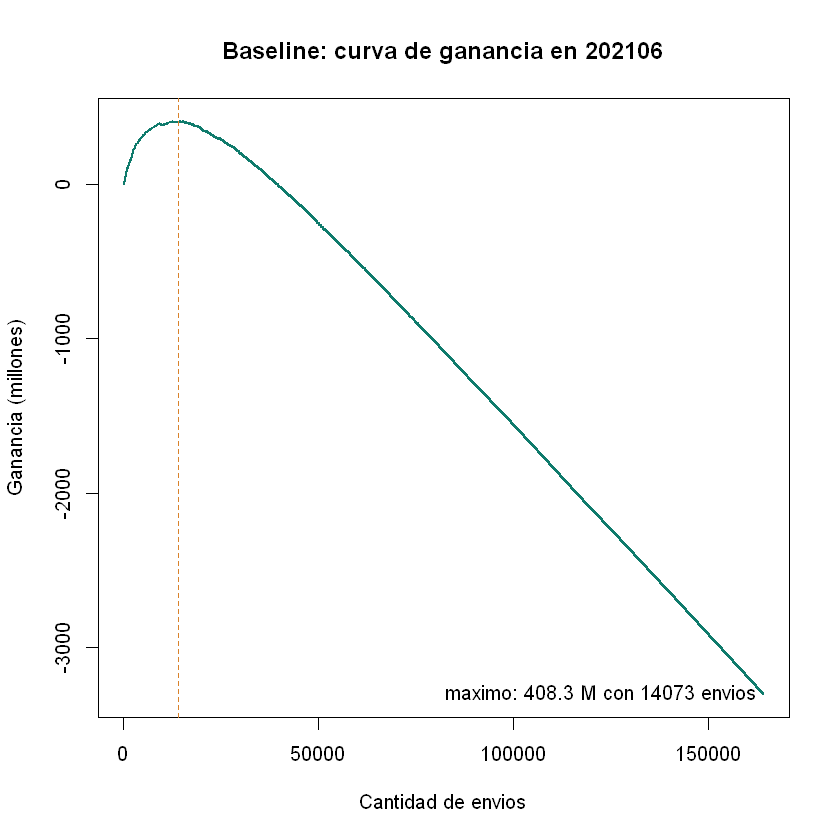

In [31]:
plot(tb_prediccion$pos, tb_prediccion$ganancia_acumulada / 1e6, type = "l", lwd = 2, col = "#0F7B6C",
     xlab = "Cantidad de envios", ylab = "Ganancia (millones)", main = "Baseline: curva de ganancia en 202106")
abline(v = envios_max, lty = 2, col = "#D9822B")
legend("bottomright", legend = paste0("maximo: ", round(ganancia_max / 1e6, 1), " M con ", envios_max, " envios"), bty = "n")

In [32]:
# Tabla de referencia: ganancia en cortes FIJOS (ensamble y por semilla) en 202106
cortes_ref <- sort(unique(c(PARAM$cortes, 10600, 12000)))

# ganancia acumulada de cada semilla (filas = ranking, columnas = semillas)
gan_acum_semilla <- sapply(seq_along(semillas_finales), function(j) {
  cumsum(gan_cliente[order(-prob_semillas[, j])])
})

tabla_ref <- data.table(
  envios            = cortes_ref,
  ensamble_M        = tb_prediccion$ganancia_acumulada[cortes_ref] / 1e6,
  semilla_media_M   = sapply(cortes_ref, function(e) mean(gan_acum_semilla[e, ])) / 1e6,
  semilla_sd_M      = sapply(cortes_ref, function(e) sd(gan_acum_semilla[e, ])) / 1e6,
  semilla_min_M     = sapply(cortes_ref, function(e) min(gan_acum_semilla[e, ])) / 1e6,
  semilla_max_M     = sapply(cortes_ref, function(e) max(gan_acum_semilla[e, ])) / 1e6
)

# rango de envios donde el ensamble queda a menos de 1 desvio por semilla del maximo
sd_ref <- mean(tabla_ref$semilla_sd_M)
max_ens <- max(tb_prediccion$ganancia_acumulada) / 1e6
cat("Maximo del ensamble:", round(max_ens, 2), "M | desvio medio por semilla:", round(sd_ref, 2), "M\n")
cat("Cortes a menos de 1 desvio del maximo:",
    paste(tabla_ref[ensamble_M >= max_ens - sd_ref, envios], collapse = ", "), "\n\n")

print(tabla_ref[, lapply(.SD, round, 2), .SDcols = names(tabla_ref)])
fwrite(tabla_ref, "tabla_referencia_cortes_fijos.csv")

Maximo del ensamble: 408.29 M | desvio medio por semilla: 7.99 M
Cortes a menos de 1 desvio del maximo: 12000, 12500, 13500, 14000, 14500, 15000 

    envios ensamble_M semilla_media_M semilla_sd_M semilla_min_M semilla_max_M
     <num>      <num>           <num>        <num>         <num>         <num>
 1:   9000     390.50          376.86         6.50        370.70        389.40
 2:   9500     385.55          382.58         6.56        373.45        393.25
 3:  10000     385.00          386.65         9.10        369.60        398.20
 4:  10500     386.65          388.41         8.40        372.35        394.35
 5:  10600     390.50          388.30         8.10        374.00        394.90
 6:  11000     390.50          390.06         6.23        378.40        400.40
 7:  11500     396.55          391.93         6.58        381.15        399.85
 8:  12000     403.70          391.38         7.56        379.50        402.60
 9:  12500     402.05          392.04         8.78        378.9